In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = pd.read_csv("waterQuality1.csv")

In [2]:
print(df.columns)

Index(['aluminium', 'ammonia', 'arsenic', 'barium', 'cadmium', 'chloramine',
       'chromium', 'copper', 'flouride', 'bacteria', 'viruses', 'lead',
       'nitrates', 'nitrites', 'mercury', 'perchlorate', 'radium', 'selenium',
       'silver', 'uranium', 'is_safe'],
      dtype='object')


In [3]:
print("--- 1. Data Dimensions (Shape) ---")
print(df.shape)
print("\n--- First 5 rows ---")
print(df.head())

print("=== General Data Information (df.info) ===")
df.info()

print("\n=== General Statistical Summary (df.describe) ===")
print(df.describe())


--- 1. Data Dimensions (Shape) ---
(7999, 21)

--- First 5 rows ---
   aluminium ammonia  arsenic  barium  cadmium  chloramine  chromium  copper  \
0       1.65    9.08     0.04    2.85    0.007        0.35      0.83    0.17   
1       2.32   21.16     0.01    3.31    0.002        5.28      0.68    0.66   
2       1.01   14.02     0.04    0.58    0.008        4.24      0.53    0.02   
3       1.36   11.33     0.04    2.96    0.001        7.23      0.03    1.66   
4       0.92   24.33     0.03    0.20    0.006        2.67      0.69    0.57   

   flouride  bacteria  ...   lead  nitrates  nitrites  mercury  perchlorate  \
0      0.05      0.20  ...  0.054     16.08      1.13    0.007        37.75   
1      0.90      0.65  ...  0.100      2.01      1.93    0.003        32.26   
2      0.99      0.05  ...  0.078     14.16      1.11    0.006        50.28   
3      1.08      0.71  ...  0.016      1.41      1.29    0.004         9.12   
4      0.61      0.13  ...  0.117      6.74      1.11   

In [4]:
for col in df.columns:

    print("\n====================")
    print("Column:", col)


    if df[col].dtype == 'object':
        print("Type: Qualitative")
    else:
        print("Type: Quantitative")


    print("Data Type:", df[col].dtype)


    print("Unique Values:", df[col].nunique())


    print("Missing Values:", df[col].isnull().sum())


    if df[col].dtype == 'object':
        print("Most Frequent Values:")
        print(df[col].value_counts().head())


    else:
        print(df[col].describe())


Column: aluminium
Type: Quantitative
Data Type: float64
Unique Values: 495
Missing Values: 0
count    7999.000000
mean        0.666158
std         1.265145
min         0.000000
25%         0.040000
50%         0.070000
75%         0.280000
max         5.050000
Name: aluminium, dtype: float64

Column: ammonia
Type: Qualitative
Data Type: object
Unique Values: 2564
Missing Values: 0
Most Frequent Values:
ammonia
0.17     13
0.37     13
0.12     13
13.74    12
0.75     11
Name: count, dtype: int64

Column: arsenic
Type: Quantitative
Data Type: float64
Unique Values: 107
Missing Values: 0
count    7999.000000
mean        0.161445
std         0.252590
min         0.000000
25%         0.030000
50%         0.050000
75%         0.100000
max         1.050000
Name: arsenic, dtype: float64

Column: barium
Type: Quantitative
Data Type: float64
Unique Values: 480
Missing Values: 0
count    7999.000000
mean        1.567715
std         1.216091
min         0.000000
25%         0.560000
50%         1

In [7]:
df = df.apply(pd.to_numeric, errors='coerce')
df.replace('#NUM!', float('nan'), inplace=True)

In [8]:
missing = df.isnull().sum()
print(missing)

aluminium      0
ammonia        3
arsenic        0
barium         0
cadmium        0
chloramine     0
chromium       0
copper         0
flouride       0
bacteria       0
viruses        0
lead           0
nitrates       0
nitrites       0
mercury        0
perchlorate    0
radium         0
selenium       0
silver         0
uranium        0
is_safe        3
dtype: int64


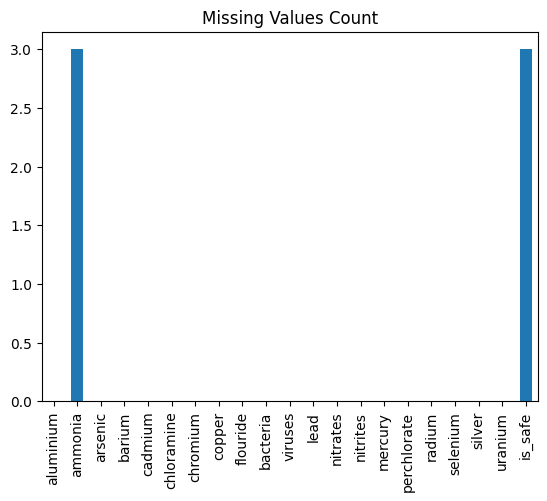

In [9]:
missing.plot(kind='bar')
plt.title("Missing Values Count")
plt.show()

In [10]:
df = df.dropna(subset=['is_safe'])

In [11]:
df = df.fillna(df.mean(numeric_only=True))

In [12]:
data_clean = df.isnull().sum()
print(data_clean)

aluminium      0
ammonia        0
arsenic        0
barium         0
cadmium        0
chloramine     0
chromium       0
copper         0
flouride       0
bacteria       0
viruses        0
lead           0
nitrates       0
nitrites       0
mercury        0
perchlorate    0
radium         0
selenium       0
silver         0
uranium        0
is_safe        0
dtype: int64


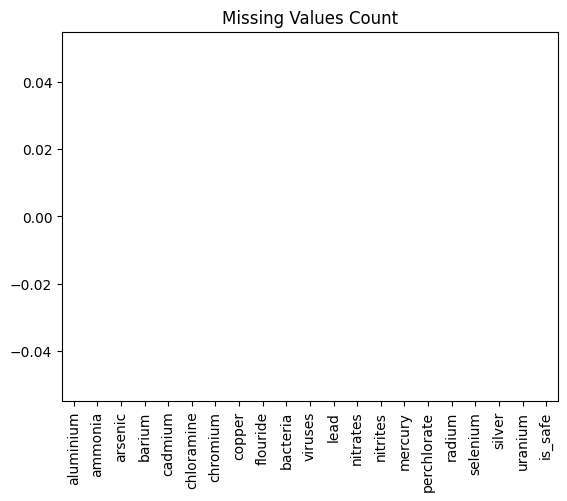

In [13]:
data_clean.plot(kind='bar')
plt.title("Missing Values Count")
plt.show()

In [14]:
corr = df.corr()

c1 = corr.abs().unstack()

c1 = c1[c1 < 1]


top_corr = c1.sort_values(ascending=False)

print(top_corr[0:10])

viruses      bacteria       0.618535
bacteria     viruses        0.618535
chloramine   perchlorate    0.588683
perchlorate  chloramine     0.588683
chloramine   chromium       0.555846
chromium     chloramine     0.555846
             perchlorate    0.524432
perchlorate  chromium       0.524432
silver       chloramine     0.522372
chloramine   silver         0.522372
dtype: float64


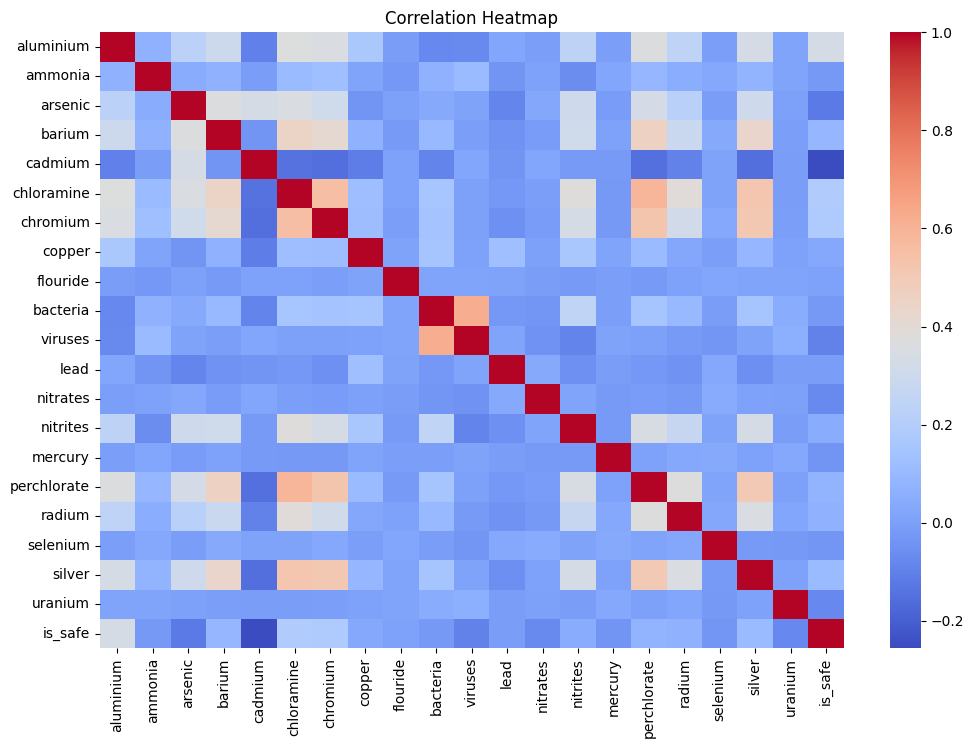

In [15]:
plt.figure(figsize=(12,8))

sns.heatmap(corr, annot=False, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

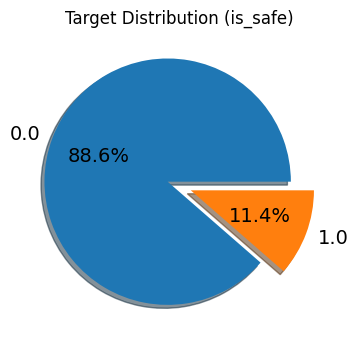

In [16]:

plt.figure(figsize=(4,4))

df['is_safe'].value_counts().plot.pie(
    explode=[0.1, 0.1],
    autopct='%1.1f%%',
    shadow=True,
    textprops={'fontsize':14}
)

plt.title("Target Distribution (is_safe)")
plt.ylabel("")
plt.show()

Target: bacteria
MAE  (Mean Absolute Error) : 0.1801
RMSE (Root Mean Sq. Error) : 0.2257
R2 Score                   : 0.5337


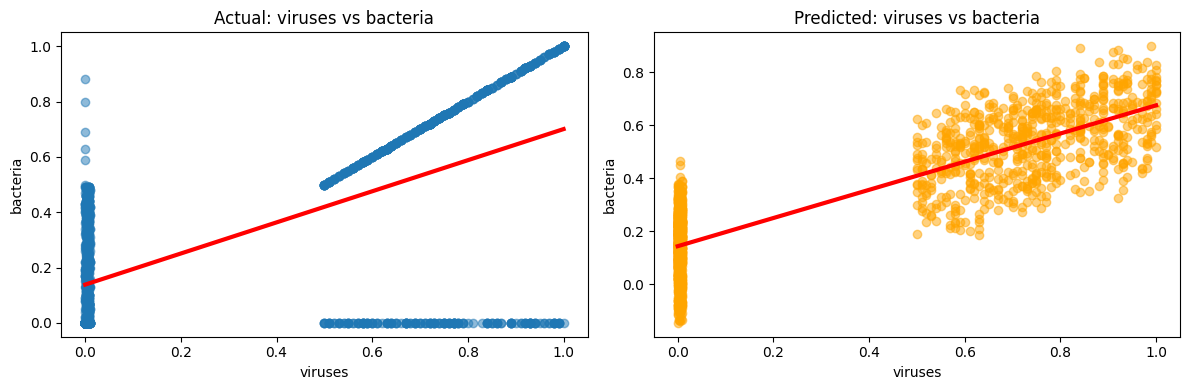

In [19]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


target_col = "bacteria"

X = df.drop(columns=["is_safe", "bacteria"])
y = df[target_col]


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LinearRegression()
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)


mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Target: {target_col}")
print(f"MAE  (Mean Absolute Error) : {mae:.4f}")
print(f"RMSE (Root Mean Sq. Error) : {rmse:.4f}")
print(f"R2 Score                   : {r2:.4f}")


top_feature = X_train.corrwith(y_train).abs().idxmax()
x_vals = X_test[top_feature]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.scatter(x_vals, y_test, alpha=0.5)
m_actual, b_actual = np.polyfit(x_vals, y_test, 1)
x_line = np.linspace(x_vals.min(), x_vals.max(), 100)
plt.plot(x_line, m_actual * x_line + b_actual, color="red", linewidth=3)
plt.title(f"Actual: {top_feature} vs {target_col}")
plt.xlabel(top_feature)
plt.ylabel(target_col)

plt.subplot(1, 2, 2)
plt.scatter(x_vals, y_pred, alpha=0.5, color="orange")
m_pred, b_pred = np.polyfit(x_vals, y_pred, 1)
plt.plot(x_line, m_pred * x_line + b_pred, color="red", linewidth=3)
plt.title(f"Predicted: {top_feature} vs {target_col}")
plt.xlabel(top_feature)
plt.ylabel(target_col)

plt.tight_layout()
plt.show()

Accuracy : 0.9087
Precision: 0.7143
Recall   : 0.3297

Confusion Matrix (Actual rows x Predicted cols):
                  Pred Negative (0)   Pred Positive (1)
Actual Pos (1)  | FN = 122           | TP = 60            |
Actual Neg (0)  | TN = 1394          | FP = 24            |


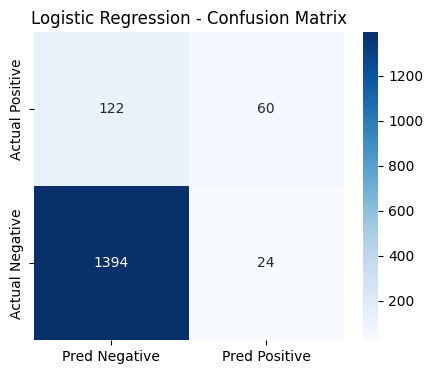

In [20]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_clf = df.drop(columns=["is_safe"])
y_clf = df["is_safe"].astype(int)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

scaler_c = StandardScaler()
X_train_c_scaled = scaler_c.fit_transform(X_train_c)
X_test_c_scaled = scaler_c.transform(X_test_c)


log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_c_scaled, y_train_c)


y_pred_log = log_model.predict(X_test_c_scaled)


acc = accuracy_score(y_test_c, y_pred_log)
prec = precision_score(y_test_c, y_pred_log, zero_division=0)
rec = recall_score(y_test_c, y_pred_log, zero_division=0)
cm = confusion_matrix(y_test_c, y_pred_log)

tn, fp, fn, tp = cm.ravel()

print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}\n")

print("Confusion Matrix (Actual rows x Predicted cols):")
print(f"                  Pred Negative (0)   Pred Positive (1)")
print(f"Actual Pos (1)  | FN = {fn:<13} | TP = {tp:<13} |")
print(f"Actual Neg (0)  | TN = {tn:<13} | FP = {fp:<13} |")


cm_display = [[fn, tp], [tn, fp]]

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_display,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Negative", "Pred Positive"],
    yticklabels=["Actual Positive", "Actual Negative"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

=== Decision Tree (criterion='gini') ===
Accuracy: 0.9606 | Precision: 0.8993 | Recall: 0.7363
[[1403   15]
 [  48  134]]


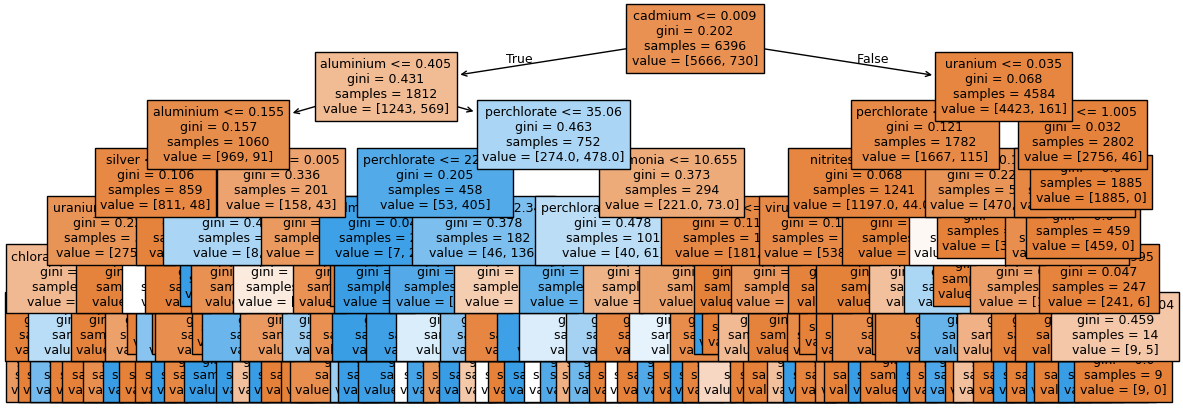

=== Decision Tree (criterion='entropy') ===
Accuracy: 0.9669 | Precision: 0.9161 | Recall: 0.7802
[[1405   13]
 [  40  142]]


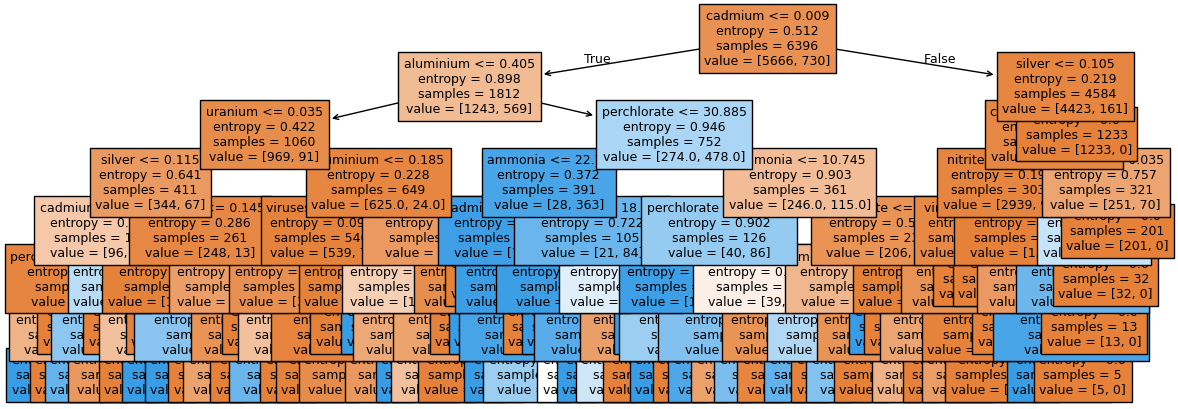

In [21]:
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score
from sklearn.tree import DecisionTreeClassifier, plot_tree

for crit in ["gini", "entropy"]:

  dt_model = DecisionTreeClassifier(
      criterion=crit, max_depth=7, random_state=42
  )
  dt_model.fit(X_train_c, y_train_c)


  y_pred_dt = dt_model.predict(X_test_c)
  dt_acc = accuracy_score(y_test_c, y_pred_dt)
  dt_prec = precision_score(y_test_c, y_pred_dt, zero_division=0)
  dt_rec = recall_score(y_test_c, y_pred_dt, zero_division=0)
  dt_cm = confusion_matrix(y_test_c, y_pred_dt)

  print(f"=== Decision Tree (criterion='{crit}') ===")
  print(
      f"Accuracy: {dt_acc:.4f} | Precision: {dt_prec:.4f} | Recall:"
      f" {dt_rec:.4f}"
  )
  print(dt_cm)

  plt.figure(figsize=(14, 5))

  plot_tree(dt_model, filled=True, fontsize=9 , feature_names=X_clf.columns)

  plt.show()

Best K: 2
Best Silhouette Score: 0.17241033002989087


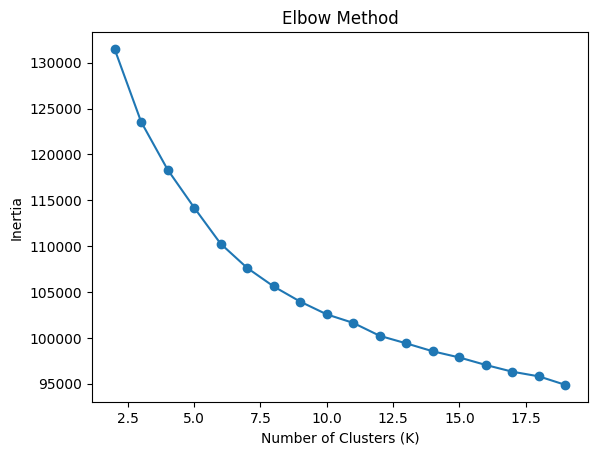

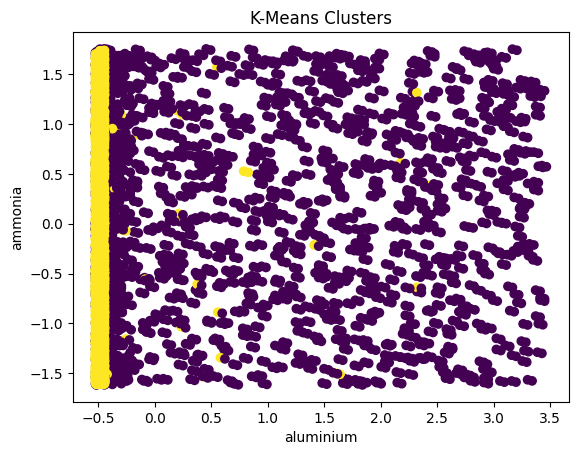

In [22]:

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score


X = df.drop(columns=["is_safe"])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)



inertia = []
scores = []
k_values = range(2, 20)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)
    scores.append(silhouette_score(X_scaled, labels))


best_k = list(k_values)[scores.index(max(scores))]

print("Best K:", best_k)
print("Best Silhouette Score:", max(scores))

plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()


kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)


plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
            c=clusters, cmap="viridis")

plt.xlabel(X.columns[0])
plt.ylabel(X.columns[1])
plt.title("K-Means Clusters")
plt.show()
